# C. Discovered Links Analysis

This notebook analyses the enriched discovered-links dataset.

The purpose is to understand the structure of the discovered links data and identify which columns are useful for the next stage: candidate URL filtering and scoring.

## 1. Analytical Questions

- How many link observations and unique URLs do we have?
- Which source organisations contribute the most observations?
- Which source pages generate many link observations?
- What do `source_page_slug_en`, `full_url_slug_en`, `url_section_en`, and `link_text_en` tell us?
- Which columns are useful for candidate filtering and scoring?

## 2. Imports

In [1]:
import os
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", str(Path("../.matplotlib-cache").resolve()))
os.environ.setdefault("MPL_IGNORE_SYSTEM_FONTS", "1")
Path(os.environ["MPLCONFIGDIR"]).mkdir(parents=True, exist_ok=True)

import matplotlib.pyplot as plt
import pandas as pd

## 3. Load Enriched Dataset

In [2]:
ENRICHED_DATA_PATH = Path("../data/interim/discovered_links_enriched.csv")

df = pd.read_csv(ENRICHED_DATA_PATH)

df.head()

,source_organisation,source_page,source_page_slug,source_page_slug_en,depth,link_text,link_text_en,href,full_url,full_url_slug,full_url_slug_en,url_section,url_section_en
0,kanker.nl,https://www.kanker.nl/,homepage,homepage,0,We zijn er voor je. Kanker.nl,We are here for you. Kanker.nl,/,https://www.kanker.nl/,homepage,homepage,homepage,homepage
1,kanker.nl,https://www.kanker.nl/,homepage,homepage,0,Blogs,Blogs,/ervaringen-van-anderen/blogs,https://www.kanker.nl/ervaringen-van-anderen/b...,blogs,blogs,ervaringen-van-anderen,others' experiences
2,kanker.nl,https://www.kanker.nl/,homepage,homepage,0,In gesprek met elkaar,Talking to each other,/ervaringen-van-anderen/gespreksgroepen,https://www.kanker.nl/ervaringen-van-anderen/g...,gespreksgroepen,discussion groups,ervaringen-van-anderen,others' experiences
3,kanker.nl,https://www.kanker.nl/,homepage,homepage,0,Diagnose,Diagnosis,/diagnose,https://www.kanker.nl/diagnose,diagnose,diagnosis,diagnose,diagnosis
4,kanker.nl,https://www.kanker.nl/,homepage,homepage,0,Werk & kanker,Work & cancer,/werk,https://www.kanker.nl/werk,werk,work,werk,work


## 4. Helper Function

In [3]:
def plot_horizontal_counts(counts, title, x_label, y_label, figsize=(10, 7)):
    plt.figure(figsize=figsize)
    counts.sort_values().plot(kind="barh")
    plt.title(title)
    plt.xlabel(x_label)
    plt.ylabel(y_label)
    plt.tight_layout()
    plt.show()

## 5. Dataset Overview

In [4]:
overview_df = pd.DataFrame([
    {"metric": "link_observations", "value": len(df)},
    {"metric": "columns", "value": df.shape[1]},
    {"metric": "unique_full_urls", "value": df["full_url"].nunique()},
    {"metric": "unique_source_pages", "value": df["source_page"].nunique()},
    {"metric": "source_organisations", "value": df["source_organisation"].nunique()},
    {"metric": "max_depth", "value": df["depth"].max()},
])

overview_df

,metric,value
0,link_observations,20856
1,columns,13
2,unique_full_urls,3851
3,unique_source_pages,257
4,source_organisations,6
5,max_depth,2


### Observation

Each row is a link observation, not necessarily a unique URL. The gap between link observations and unique URLs shows that the same destination URL can be discovered multiple times from different source pages.

## 6. Source Organisation Analysis

In [5]:
source_organisation_summary_df = (
    df
    .groupby("source_organisation", dropna=False)
    .agg(
        link_observations=("full_url", "size"),
        unique_urls=("full_url", "nunique"),
        unique_source_pages=("source_page", "nunique"),
        max_depth=("depth", "max"),
    )
    .reset_index()
    .sort_values("link_observations", ascending=False)
)

source_organisation_summary_df

,source_organisation,link_observations,unique_urls,unique_source_pages,max_depth
0,iknl.nl,5821,502,39,1
1,kanker.nl,4566,1305,50,1
2,nfk.nl,4447,210,40,1
3,thuisarts.nl,3626,1318,50,1
5,zorgwijzer.nl,1451,292,39,2
4,zorginstituutnederland.nl,945,224,39,2


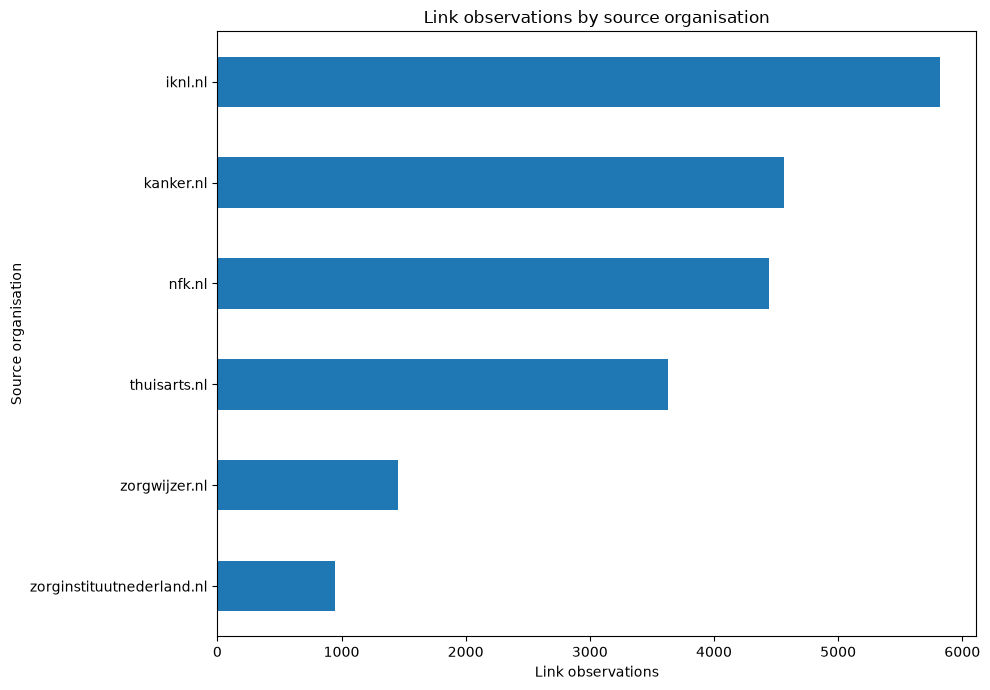

In [6]:
counts = df["source_organisation"].value_counts()

plot_horizontal_counts(
    counts=counts,
    title="Link observations by source organisation",
    x_label="Link observations",
    y_label="Source organisation",
)

### Observation

Source organisation counts show where the crawl collected the most link observations. These counts are affected by crawl settings, website structure, and how many internal links each website exposes.

## 7. Unique Value Analysis

In [7]:
unique_value_summary_df = pd.DataFrame([
    {"column": "source_page", "unique_values": df["source_page"].nunique()},
    {"column": "source_page_slug_en", "unique_values": df["source_page_slug_en"].nunique()},
    {"column": "full_url", "unique_values": df["full_url"].nunique()},
    {"column": "full_url_slug_en", "unique_values": df["full_url_slug_en"].nunique()},
    {"column": "url_section_en", "unique_values": df["url_section_en"].nunique()},
    {"column": "link_text_en", "unique_values": df["link_text_en"].nunique()},
])

unique_value_summary_df

,column,unique_values
0,source_page,257
1,source_page_slug_en,244
2,full_url,3851
3,full_url_slug_en,3237
4,url_section_en,857
5,link_text_en,4126


### Observation

Slug columns improve readability, but they are not unique identifiers. Exact page-level analysis should use `source_page` or `full_url`. Slugs are better used as readable context features.

## 8. Source Page Distribution

In [8]:
source_page_counts = df["source_page"].value_counts()

print("number of unique source pages:", df["source_page"].nunique())
source_page_counts.head(20)

number of unique source pages: 257


source_page
https://www.thuisarts.nl/overzicht/onderwerpen#K                                                                             731
https://www.thuisarts.nl/overzicht/onderwerpen                                                                               731
https://www.thuisarts.nl/overzicht/videos                                                                                    266
https://www.kanker.nl/bibliotheek                                                                                            175
https://iknl.nl/nkr                                                                                                          174
https://iknl.nl/nkr/uitleg-nkr-cijfers                                                                                       173
https://www.kanker.nl/gevolgen-van-kanker/niet-meer-beter-worden/niet-meer-beter-worden/als-genezen-niet-meer-mogelijk-is    172
https://www.kanker.nl/kankersoorten/borstkanker/algemeen/wat-is-borstkanker          

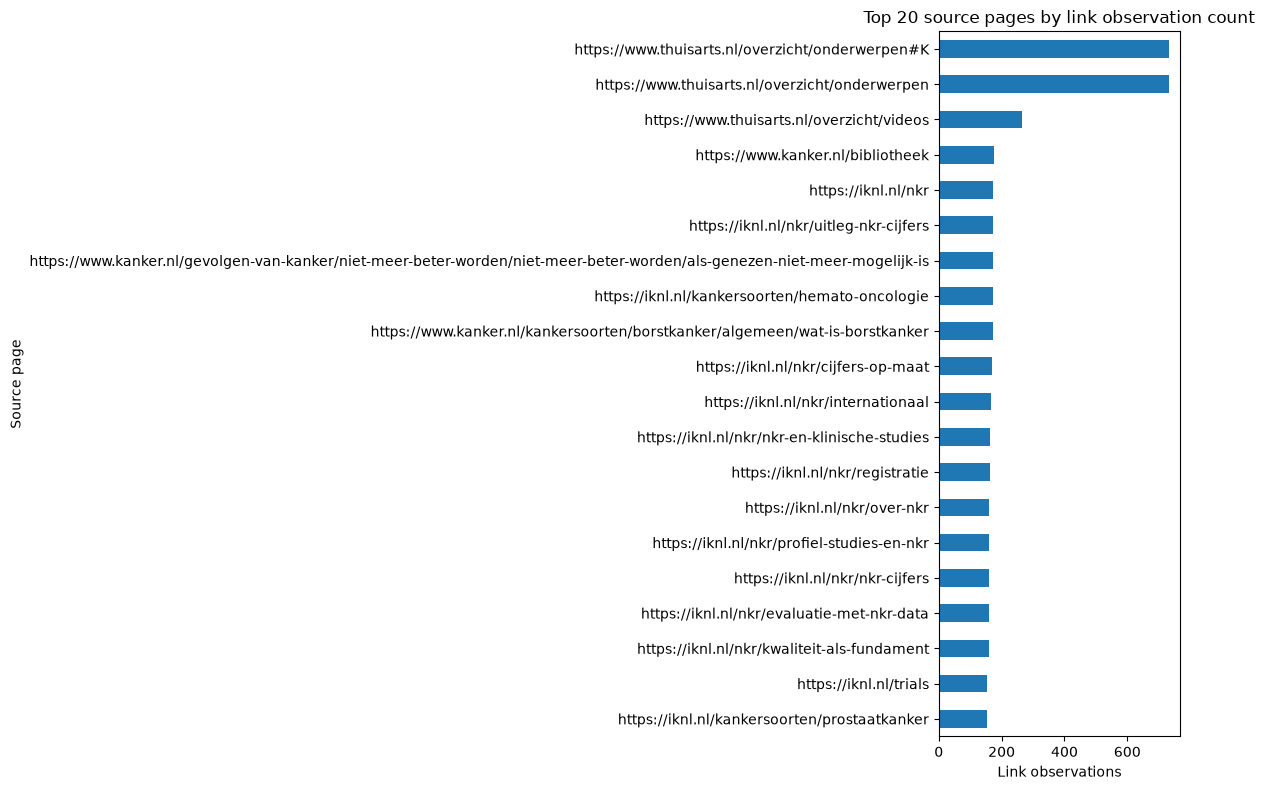

In [9]:
plot_horizontal_counts(
    counts=source_page_counts.head(20),
    title="Top 20 source pages by link observation count",
    x_label="Link observations",
    y_label="Source page",
    figsize=(12, 8),
)

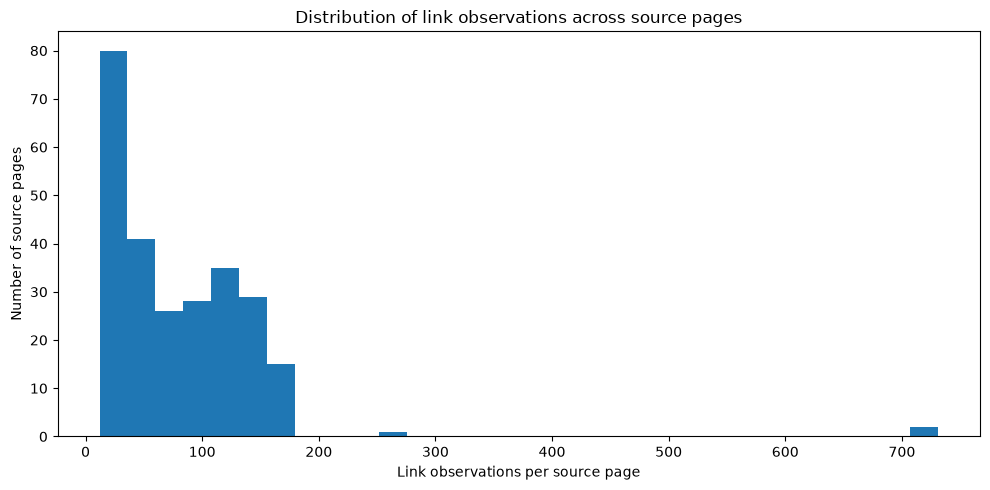

In [10]:
plt.figure(figsize=(10, 5))
source_page_counts.plot(kind="hist", bins=30)
plt.title("Distribution of link observations across source pages")
plt.xlabel("Link observations per source page")
plt.ylabel("Number of source pages")
plt.tight_layout()
plt.show()

### Observation

The distribution helps show whether link observations are concentrated in a small number of source pages or spread evenly. Highly linked source pages may be hub pages, topic indexes, home pages, or navigation pages.

## 9. Source Page Slug Analysis

In [11]:
source_page_slug_counts = df["source_page_slug_en"].value_counts()

print("number of unique source_page_slug_en:", df["source_page_slug_en"].nunique())
source_page_slug_counts.head(20)

number of unique source_page_slug_en: 244


source_page_slug_en
topics                           1462
homepage                          502
types of cancer                   280
videos                            266
projects                          242
tidings                           237
skin cancer                       223
cervical cancer                   184
library                           175
uterine cancer                    175
nkr                               174
explanation of nkr figures        173
if-cure-is no longer possible     172
what-is breast cancer             171
hemato-oncology                   171
customized numbers                170
pancreatic cancer                 168
internationally                   167
NKR and clinical studies          163
registration                      162
Name: count, dtype: int64

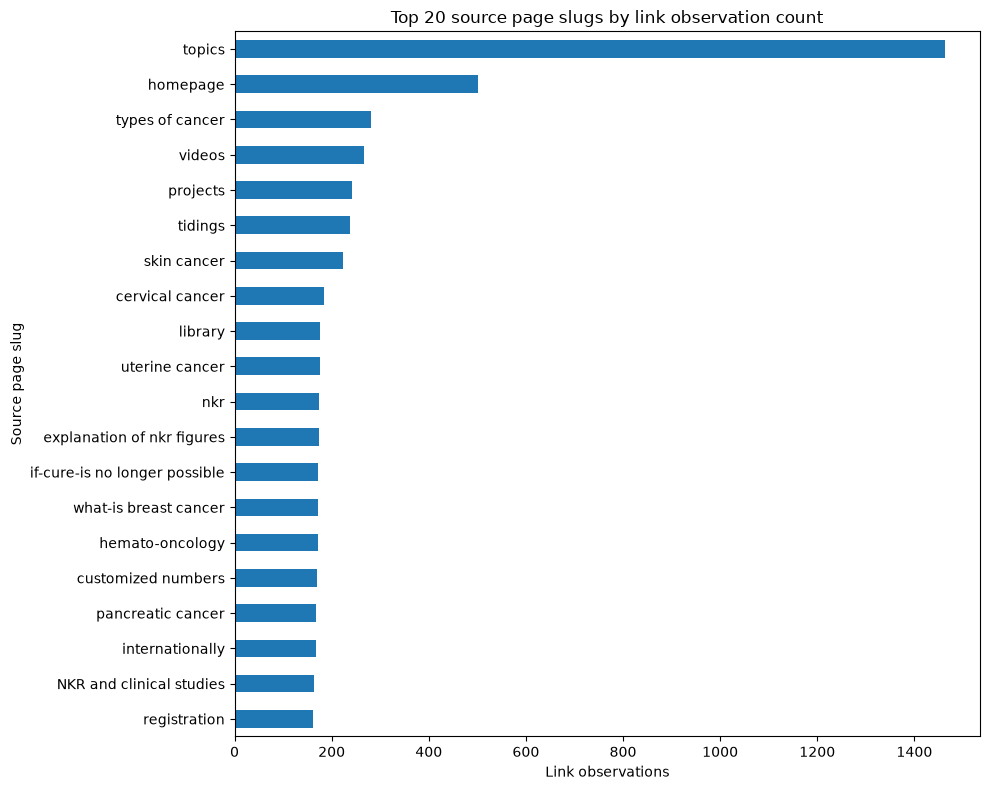

In [12]:
plot_horizontal_counts(
    counts=source_page_slug_counts.head(20),
    title="Top 20 source page slugs by link observation count",
    x_label="Link observations",
    y_label="Source page slug",
    figsize=(10, 8),
)

In [13]:
source_slug_uniqueness_df = (
    df
    .groupby("source_page_slug_en", dropna=False)
    .agg(
        link_observations=("source_page_slug_en", "size"),
        unique_source_pages=("source_page", "nunique"),
        source_organisations=("source_organisation", "nunique"),
    )
    .reset_index()
    .sort_values(["unique_source_pages", "link_observations"], ascending=False)
)

source_slug_uniqueness_df.head(20)

,source_page_slug_en,link_observations,unique_source_pages,source_organisations
116,homepage,502,5,5
197,topics,1462,2,1
200,types of cancer,280,2,2
170,projects,242,2,2
195,tidings,237,2,2
185,skin cancer,223,2,2
67,cervical cancer,184,2,2
204,uterine cancer,175,2,2
153,pancreatic cancer,168,2,2
142,organization,140,2,2


### Observation

`source_page_slug_en` improves readability, but it is not unique. Different source pages can share the same slug, especially across organisations. For more accurate analysis, use it together with `source_organisation` or the exact `source_page`.

## 10. Organisation + Source Page Slug Analysis

In [14]:
organisation_source_slug_counts = (
    df["source_organisation"].astype(str)
    + " - "
    + df["source_page_slug_en"].astype(str)
).value_counts().head(20)

organisation_source_slug_counts

thuisarts.nl - topics                                         1462
thuisarts.nl - videos                                          266
kanker.nl - library                                            175
iknl.nl - nkr                                                  174
iknl.nl - explanation of nkr figures                           173
kanker.nl - if-cure-is no longer possible                      172
kanker.nl - what-is breast cancer                              171
iknl.nl - hemato-oncology                                      171
iknl.nl - customized numbers                                   170
iknl.nl - internationally                                      167
iknl.nl - NKR and clinical studies                             163
iknl.nl - registration                                         162
iknl.nl - about nkr                                            160
iknl.nl - profile-studies-en-nkr                               160
iknl.nl - nkr figures                                         

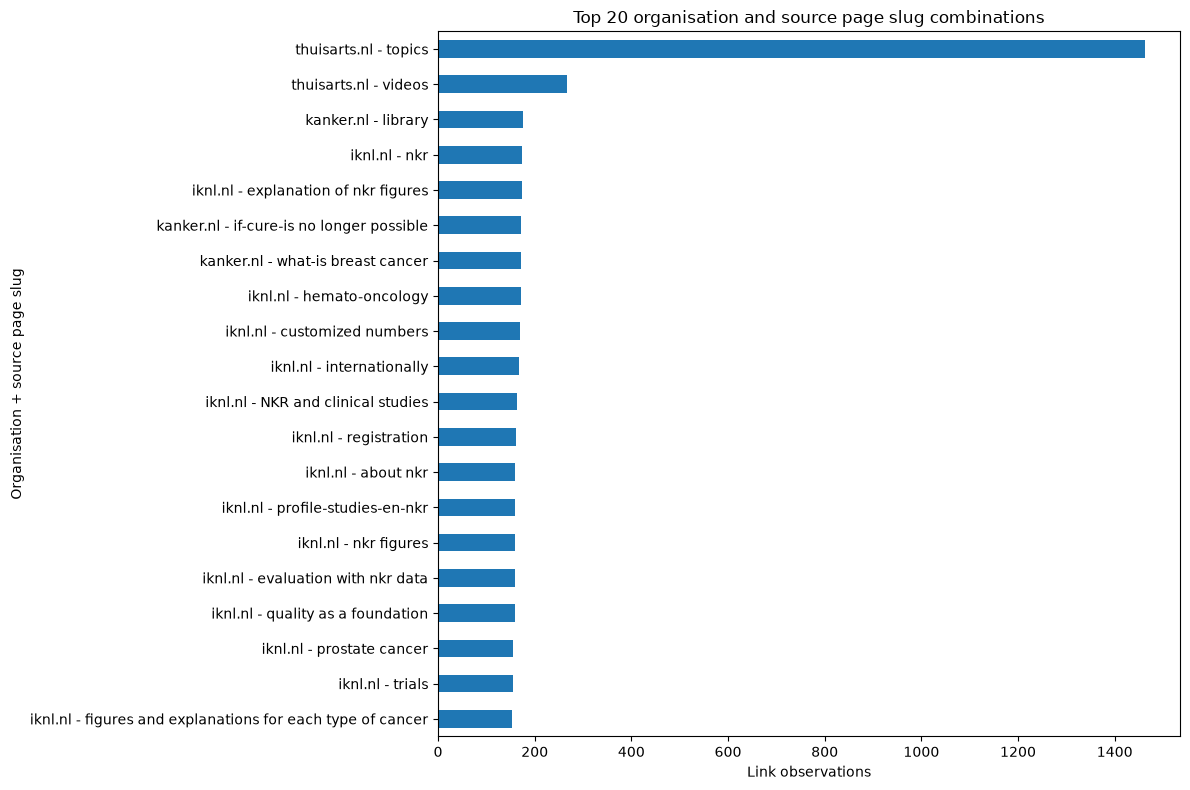

In [15]:
plot_horizontal_counts(
    counts=organisation_source_slug_counts,
    title="Top 20 organisation and source page slug combinations",
    x_label="Link observations",
    y_label="Organisation + source page slug",
    figsize=(12, 8),
)

### Observation

Combining `source_organisation` with `source_page_slug_en` reduces ambiguity and makes source-page labels easier to interpret. Exact source-page analysis should still use the full `source_page` URL.

## 11. Full URL Slug Analysis

In [16]:
full_url_slug_counts = df["full_url_slug_en"].value_counts()

print("number of unique full_url_slug_en:", df["full_url_slug_en"].nunique())
full_url_slug_counts.head(20)

number of unique full_url_slug_en: 3237


full_url_slug_en
homepage                      477
tidings                       265
patient participation         245
types of cancer               195
disclaimer                    168
contact-with-nfk              160
urgently who will you call    150
themes                        135
contact                       128
remuneration                  127
compare health insurance      124
scientific publications       121
projects                      120
contact address               118
privacy policy                118
health insurer                116
elective cards                103
topics                        100
videos                        100
pictures                      100
Name: count, dtype: int64

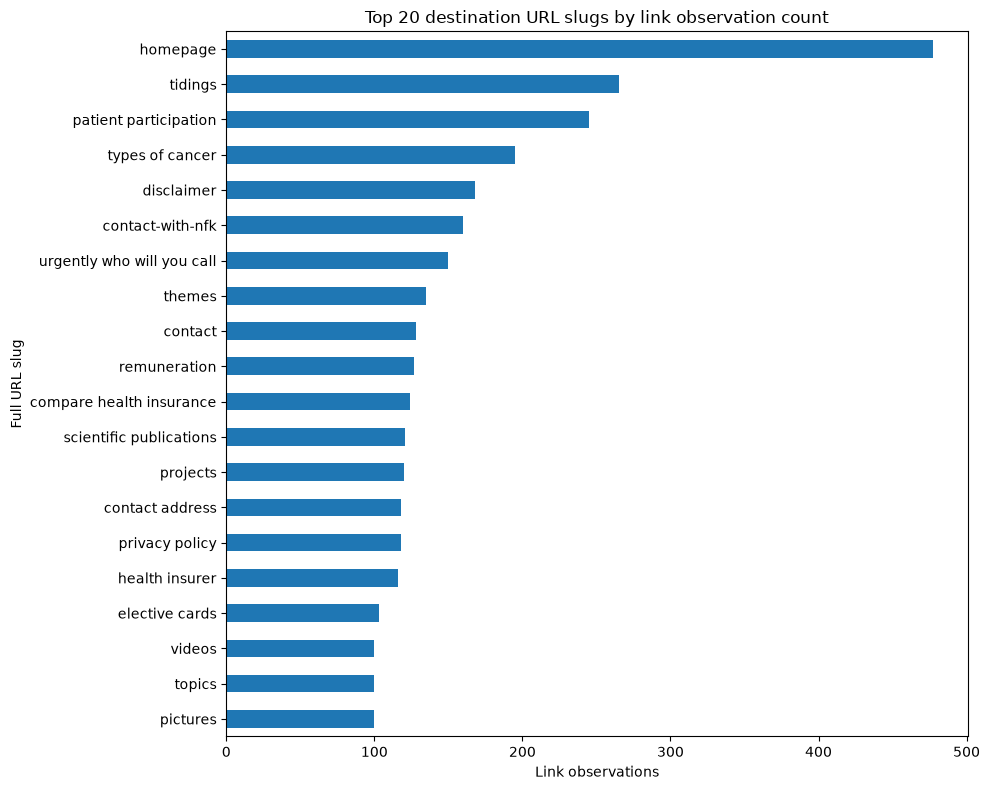

In [17]:
plot_horizontal_counts(
    counts=full_url_slug_counts.head(20),
    title="Top 20 destination URL slugs by link observation count",
    x_label="Link observations",
    y_label="Full URL slug",
    figsize=(10, 8),
)

In [18]:
full_url_slug_uniqueness_df = (
    df
    .groupby("full_url_slug_en", dropna=False)
    .agg(
        link_observations=("full_url_slug_en", "size"),
        unique_full_urls=("full_url", "nunique"),
        source_organisations=("source_organisation", "nunique"),
    )
    .reset_index()
    .sort_values(["unique_full_urls", "link_observations"], ascending=False)
)

full_url_slug_uniqueness_df.head(20)

,full_url_slug_en,link_observations,unique_full_urls,source_organisations
985,download,71,71,1
2861,tidings,265,22,3
2455,research,96,20,1
2369,public,38,19,1
2009,numerals,26,18,1
2908,treatment,18,18,1
2118,palliative phase,17,16,1
2941,trials,53,15,2
244,about the numbers,14,14,1
1654,life after cancer,15,13,1


### Observation

`full_url_slug_en` describes the destination page rather than the source page. This makes it especially useful for candidate URL filtering, because the next stage decides which destination URLs should be reviewed or scraped.

## 12. URL Section Analysis

In [19]:
url_section_counts = df["url_section_en"].value_counts()

print("number of unique url_section_en:", df["url_section_en"].nunique())
url_section_counts.head(25)

number of unique url_section_en: 857


url_section_en
types of cancer           3229
themes                    1445
nkr                        902
organization               867
overview                   802
about iknl                 585
cancer atlas               509
patient participation      490
types of treatments        484
homepage                   477
cancer and life            429
our goals                  417
help and support           402
consequences of cancer     399
palliative care            390
insights                   384
service                    382
remuneration               372
others' experiences        369
and                        351
topical                    319
insured care               313
wherewithal                303
expensive drugs            242
about us                   196
Name: count, dtype: int64

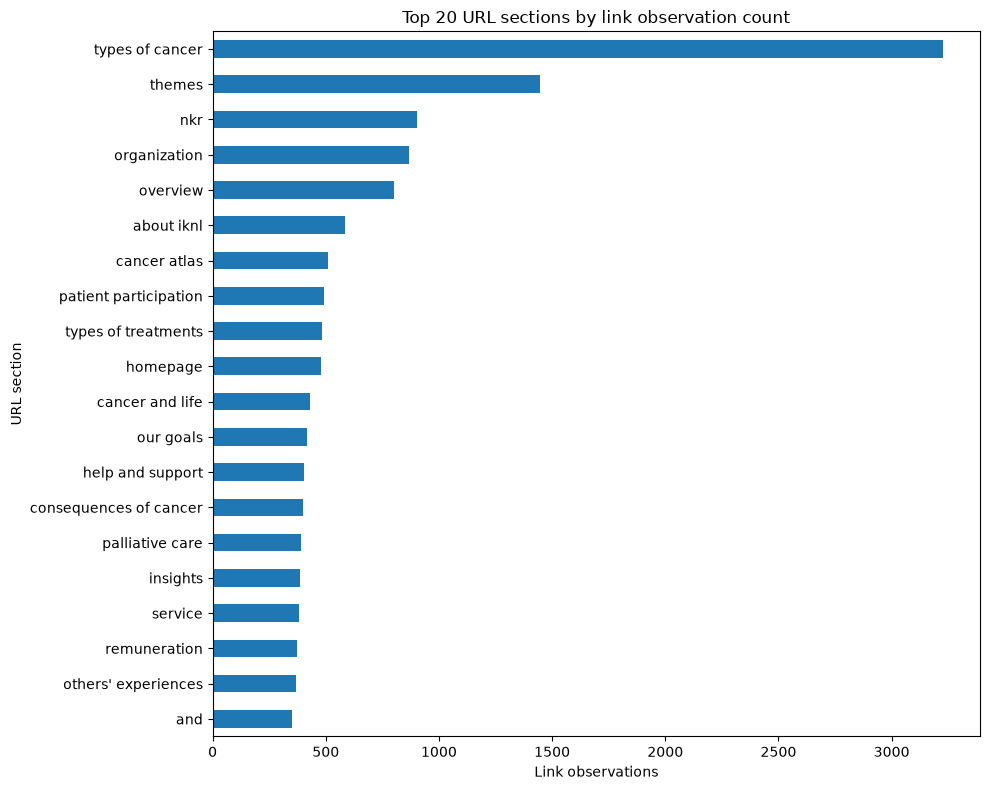

In [20]:
plot_horizontal_counts(
    counts=url_section_counts.head(20),
    title="Top 20 URL sections by link observation count",
    x_label="Link observations",
    y_label="URL section",
    figsize=(10, 8),
)

In [21]:
url_section_by_org_df = (
    df
    .groupby(["source_organisation", "url_section_en"], dropna=False)
    .agg(
        link_observations=("full_url", "size"),
        unique_urls=("full_url", "nunique"),
    )
    .reset_index()
    .sort_values("link_observations", ascending=False)
)

url_section_by_org_df.head(25)

,source_organisation,url_section_en,link_observations,unique_urls
83,kanker.nl,types of cancer,1829,717
41,iknl.nl,types of cancer,1400,222
108,nfk.nl,themes,1249,47
28,iknl.nl,nkr,902,47
99,nfk.nl,organization,867,26
577,thuisarts.nl,overview,802,307
4,iknl.nl,about iknl,585,30
7,iknl.nl,cancer atlas,509,13
102,nfk.nl,patient participation,490,6
84,kanker.nl,types of treatments,484,126


### Observation

`url_section_en` gives a high-level website area. It can help identify likely relevant sections, such as support or treatment areas, and possible noise sections, such as contact, news, jobs, privacy, or cookie pages.

## 13. Link Text Analysis

In [22]:
link_text_counts = df["link_text_en"].value_counts()

print("number of unique link_text_en:", df["link_text_en"].nunique())
link_text_counts.head(25)

number of unique link_text_en: 4126


link_text_en
News                              304
Contact                           208
Guidelines                        170
Disclaimer                        167
Patient participation             165
Urgent: who to call?              150
Scientific research               130
Privacy statement                 129
Fees                              126
Organization                      123
Projects                          120
Scientific publications           120
Compare health insurance          113
Choice cards                      102
We are here for you. Kanker.nl    100
All complaints and illnesses      100
videos                            100
Pictures                          100
Decision aids                     100
Search by body part               100
read more                          99
Pancreatic cancer                  98
Breast cancer                      97
Lung cancer                        97
Prostate Cancer                    97
Name: count, dtype: int64

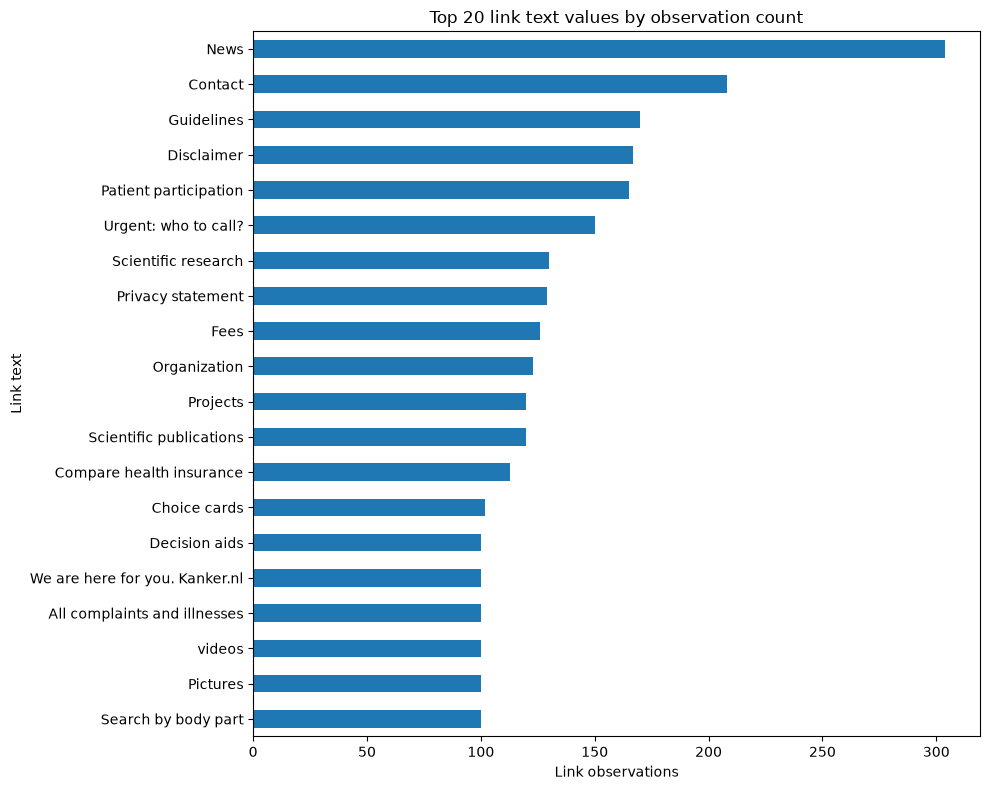

In [23]:
plot_horizontal_counts(
    counts=link_text_counts.head(20),
    title="Top 20 link text values by observation count",
    x_label="Link observations",
    y_label="Link text",
    figsize=(10, 8),
)

### Observation

`link_text_en` provides the visible label users see on the page. It is useful for filtering because relevant links often contain patient-navigation terms, while repeated generic labels may indicate menus, buttons, navigation links, or noise.

## 14. Duplicate URL Analysis

In [24]:
duplicate_url_summary_df = (
    df
    .groupby("full_url", dropna=False)
    .agg(
        discovery_count=("full_url", "size"),
        unique_source_pages=("source_page", "nunique"),
        source_organisations=("source_organisation", "nunique"),
        full_url_slug_en=("full_url_slug_en", "first"),
        link_text_examples=("link_text_en", lambda values: "; ".join(list(dict.fromkeys(values.dropna().astype(str)))[:5])),
    )
    .reset_index()
    .sort_values(["source_organisations", "unique_source_pages", "discovery_count"], ascending=False)
)

duplicate_url_summary_df.head(25)

,full_url,discovery_count,unique_source_pages,source_organisations,full_url_slug_en,link_text_examples
3161,https://www.thuisarts.nl/spoed-wie-bel-je,150,50,1,urgently who will you call,Urgent: who to call?
1118,https://www.kanker.nl/kankersoorten,117,50,1,types of cancer,See all cancers (A-Z); More types of cancer; T...
698,https://www.kanker.nl/,101,50,1,homepage,We are here for you. Kanker.nl; cancer.nl
2066,https://www.thuisarts.nl/anatomisch,100,50,1,anatomically,Search by body part
2782,https://www.thuisarts.nl/overzicht/afbeeldingen,100,50,1,pictures,Pictures
2783,https://www.thuisarts.nl/overzicht/keuzehulpen,100,50,1,decision aids,Decision aids
2784,https://www.thuisarts.nl/overzicht/keuzekaarten,100,50,1,elective cards,Choice cards
2785,https://www.thuisarts.nl/overzicht/onderwerpen,100,50,1,topics,All complaints and illnesses
3026,https://www.thuisarts.nl/overzicht/videos,100,50,1,videos,videos
1056,https://www.kanker.nl/hulp-en-ondersteuning/st...,72,50,1,ask a professional your question,Ask a pro; professionals; Ask a pro Ask an exp...


### Observation

URLs discovered many times may be important hub pages, repeated navigation links, or common support resources. Discovery frequency can become one signal in candidate URL scoring, but it should not be used alone.

## 15. Summary: Useful Columns For Next Stage

Useful columns for candidate filtering and scoring:

- `full_url`: exact destination URL and the main unit for deduplication.
- `source_organisation`: helps preserve source trust and compare coverage.
- `source_page`: exact page where a link was discovered.
- `source_page_slug_en`: readable source-page context, but not unique.
- `full_url_slug_en`: readable destination-page topic and likely useful for filtering.
- `url_section_en`: high-level website area that can reveal useful sections or noise sections.
- `link_text_en`: visible link label and strong keyword-matching signal.
- `depth`: crawl-depth metadata that may help identify broad navigation pages versus deeper content.

Next notebook should use these columns to create candidate URL filtering and scoring rules.